# Análisis exploratorio: presión del acumulador

**Grupo G7 · Luis Anchundia · 22/oct/2026**

Este notebook usa **solo entrenamiento** mediante `cargar_entrenamiento()`. El conjunto de prueba queda reservado para la evaluación única del 27/oct. Cada fila corresponde a un ciclo de 60 s y contiene 68 estadísticas extraídas de 17 sensores. La etiqueta `clase` codifica 90, 100, 115 y 130 bar como 0, 1, 2 y 3.

Objetivos: verificar calidad y distribución, cuantificar el efecto de grupos grandes, detectar redundancia entre variables y proponer 2 o 3 mediciones de presión para la explicación difusa de José.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

from ic_g7 import config
from ic_g7.datos import cargar_entrenamiento
from ic_g7.evaluacion import crear_cv

X, y, grupos = cargar_entrenamiento()
clases_bar = {v: k for k, v in config.CLASE_POR_OBJETIVO.items()}
print(f"Entrenamiento: {len(X)} ciclos, {X.shape[1]} variables, {grupos.nunique()} grupos")
print("Orden de clases:", clases_bar)

Entrenamiento: 1827 ciclos, 68 variables, 111 grupos
Orden de clases: {0: 90, 1: 100, 2: 115, 3: 130}


## 1. Tamaño, calidad y balance de clases

Se comprueban nulos, infinitos, columnas constantes y filas de sensores idénticas en las 68 variables generadas del conjunto de entrenamiento.

,valor
ciclos,1827
variables,68
valores_nulos,0
valores_no_finitos,0
filas_de_sensores_duplicadas,0
columnas_constantes,4


Columnas constantes: ['PS2_min', 'PS3_min', 'FS1_min', 'SE_min']


,ciclos,porcentaje
clase,,
90,686,37.5
100,317,17.4
115,317,17.4
130,507,27.8


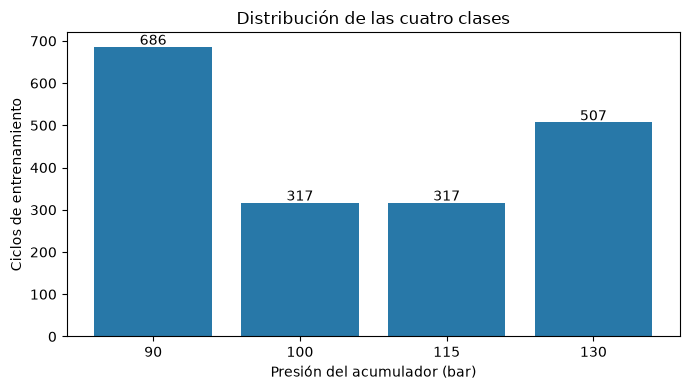

In [2]:
calidad = pd.Series({
    "ciclos": len(X),
    "variables": X.shape[1],
    "valores_nulos": int(X.isna().sum().sum()),
    "valores_no_finitos": int((~np.isfinite(X.to_numpy())).sum()),
    "filas_de_sensores_duplicadas": int(X.duplicated().sum()),
    "columnas_constantes": int((X.nunique() <= 1).sum()),
})
display(calidad.to_frame("valor"))
print("Columnas constantes:", X.columns[X.nunique() <= 1].tolist())
conteos = y.value_counts().sort_index().rename(index=clases_bar)
display(pd.DataFrame({"ciclos": conteos, "porcentaje": (conteos / len(y) * 100).round(1)}))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([str(c) for c in conteos.index], conteos.values, color="#2878a8")
ax.set(xlabel="Presión del acumulador (bar)", ylabel="Ciclos de entrenamiento",
       title="Distribución de las cuatro clases")
for i, valor in enumerate(conteos.values):
    ax.text(i, valor + 5, str(valor), ha="center")
plt.tight_layout()
plt.show()

## 2. Grupos y sesgo de validación

`group_id` representa una combinación completa de estados de los cuatro componentes. La validación debe mantener cada grupo en un solo lado del pliegue. Los tres grupos más grandes pueden dominar los pliegues; por ello se deben informar métricas por pliegue, además de media y desviación.

,valor
grupos_entrenamiento,111.0
tam_minimo,10.0
tam_mediano,10.0
tam_maximo,230.0
tres_mayores_ciclos,672.0
tres_mayores_porcentaje,36.8


,ciclos
group_id,
3,230
98,221
51,221
96,21
50,21
49,21
48,21
1,21
102,11


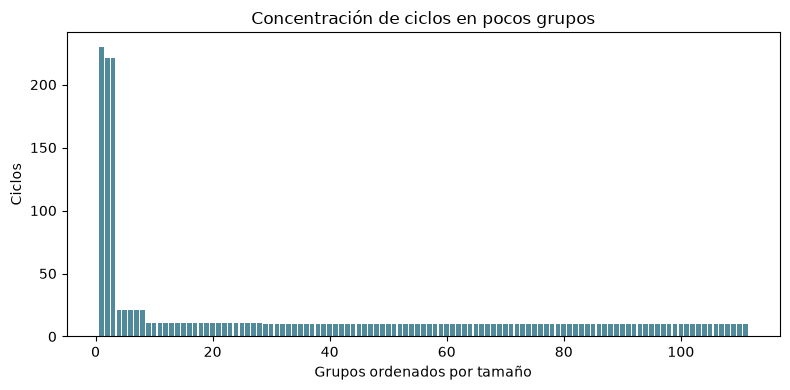

Pliegue 0: 424 ciclos; grupo mayor = 54.2%
Pliegue 1: 426 ciclos; grupo mayor = 51.9%
Pliegue 2: 416 ciclos; grupo mayor = 53.1%
Pliegue 3: 285 ciclos; grupo mayor = 7.4%
Pliegue 4: 276 ciclos; grupo mayor = 7.6%


In [3]:
tam_grupo = grupos.value_counts().sort_values(ascending=False)
resumen_grupos = pd.Series({
    "grupos_entrenamiento": len(tam_grupo),
    "tam_minimo": int(tam_grupo.min()),
    "tam_mediano": float(tam_grupo.median()),
    "tam_maximo": int(tam_grupo.max()),
    "tres_mayores_ciclos": int(tam_grupo.head(3).sum()),
    "tres_mayores_porcentaje": round(tam_grupo.head(3).sum() / len(X) * 100, 1),
})
display(resumen_grupos.to_frame("valor"))
display(tam_grupo.head(10).rename("ciclos").to_frame())
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(tam_grupo) + 1), tam_grupo.values, color="#518a9b")
ax.set(xlabel="Grupos ordenados por tamaño", ylabel="Ciclos",
       title="Concentración de ciclos en pocos grupos")
plt.tight_layout()
plt.show()
for n, (_, indice_validacion) in enumerate(crear_cv().split(X, y, grupos)):
    g_val = grupos.iloc[indice_validacion].value_counts()
    print(f"Pliegue {n}: {len(indice_validacion)} ciclos; "
          f"grupo mayor = {g_val.max() / len(indice_validacion):.1%}")

## 3. Correlación y variables redundantes

Se resumen los pares con `|r| > 0,95`, sin usar la etiqueta. El filtro de `src/ic_g7/pipeline.py` se ajusta **dentro de cada pliegue**, después del escalado. La comparación preliminar en entrenamiento mostró que `0,95` elimina demasiadas variables y reduce el F1 de la MLP; por eso el valor inicial del código es `0,995`. Esta decisión se debe interpretar como exploratoria.

Pares con |r| > 0,95: 337
Pares con |r| > 0,995: 102


|r|
PS5_mean PS6_mean  0.999992
TS3_mean TS3_max   0.999986
         TS3_min   0.999982
TS1_mean TS1_max   0.999978
PS5_max  PS6_max   0.999976
TS2_mean TS2_min   0.999969
PS5_min  PS6_min   0.999969
TS2_mean TS2_max   0.999967
TS1_mean TS1_min   0.999956
TS3_min  TS3_max   0.999950
TS4_mean TS4_max   0.999940
         TS4_min   0.999940
PS5_mean PS5_min   0.999935
PS5_min  PS6_mean  0.999934
PS5_mean PS6_max   0.999932

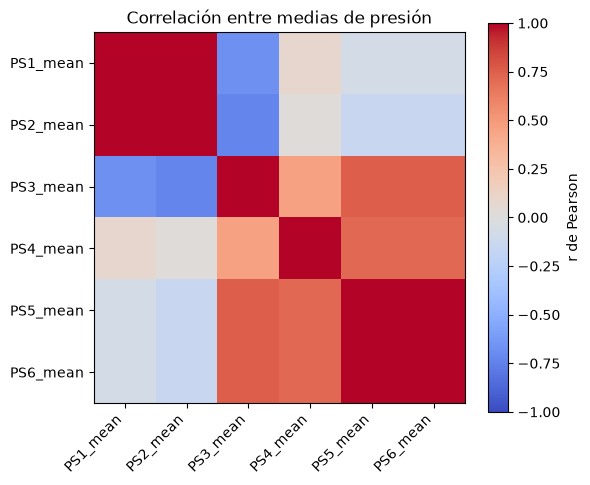

In [4]:
corr = X.corr().abs()
triangulo = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pares = triangulo.stack().sort_values(ascending=False).rename("|r|")
print(f"Pares con |r| > 0,95: {int((pares > 0.95).sum())}")
print(f"Pares con |r| > 0,995: {int((pares > 0.995).sum())}")
display(pares.head(15).to_frame())
presiones_media = [f"PS{i}_mean" for i in range(1, 7)]
fig, ax = plt.subplots(figsize=(6, 5))
mapa = ax.imshow(X[presiones_media].corr(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(6), presiones_media, rotation=45, ha="right")
ax.set_yticks(range(6), presiones_media)
ax.set_title("Correlación entre medias de presión")
fig.colorbar(mapa, ax=ax, label="r de Pearson")
plt.tight_layout()
plt.show()

## 4. Variables de presión que separan las cuatro clases

Como exploración, cada estadístico de PS1–PS6 se evalúa **por separado** con un árbol poco profundo y los mismos cinco pliegues por grupos. Este puntaje es una ayuda para escoger variables explicativas; no es el resultado final de un modelo ni una estimación de prueba. Para proponer tres variables distintas se descartan candidatas con `|r| ≥ 0,95` respecto a una ya elegida.

In [5]:
variables_presion = [c for c in X if c.startswith(("PS1_", "PS2_", "PS3_",
                                                          "PS4_", "PS5_", "PS6_"))]
filas = []
for variable in variables_presion:
    arbol = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5,
                                   random_state=config.RANDOM_STATE)
    puntajes = cross_val_score(arbol, X[[variable]], y, groups=grupos,
                               cv=crear_cv(), scoring="f1_macro")
    filas.append({"variable": variable, "F1_macro_media": puntajes.mean(),
                  "F1_macro_std": puntajes.std()})
ranking = pd.DataFrame(filas).sort_values("F1_macro_media", ascending=False)
display(ranking.head(12).round(3).reset_index(drop=True))
elegidas = []
for variable in ranking["variable"]:
    if all(abs(X[variable].corr(X[otra])) < 0.95 for otra in elegidas):
        elegidas.append(variable)
    if len(elegidas) == 3:
        break
print("Propuesta de variables para José:", elegidas)
display(ranking.set_index("variable").loc[elegidas].round(3))

,variable,F1_macro_media,F1_macro_std
0,PS5_max,0.475,0.148
1,PS6_max,0.426,0.081
2,PS6_mean,0.403,0.178
3,PS5_mean,0.354,0.103
4,PS6_min,0.354,0.102
5,PS3_mean,0.352,0.091
6,PS5_min,0.352,0.100
7,PS1_mean,0.302,0.111
8,PS1_max,0.300,0.088
9,PS2_max,0.280,0.085


Propuesta de variables para José: ['PS5_max', 'PS3_mean', 'PS1_mean']


,F1_macro_media,F1_macro_std
variable,,
PS5_max,0.475,0.148
PS3_mean,0.352,0.091
PS1_mean,0.302,0.111


PS5_max               PS3_mean               PS1_mean                  
     median    q25    q75   median    q25    q75   median      q25      q75
bar                                                                        
90    9.234  9.047  9.991    1.805  1.779  1.996  160.400  158.329  161.024
100   9.226  8.487  9.872    1.754  1.684  1.912  159.200  158.639  160.761
115   9.191  8.533  9.885    1.769  1.723  1.938  160.338  158.482  161.090
130   8.748  8.604  9.103    1.738  1.722  1.787  157.526  156.994  158.583

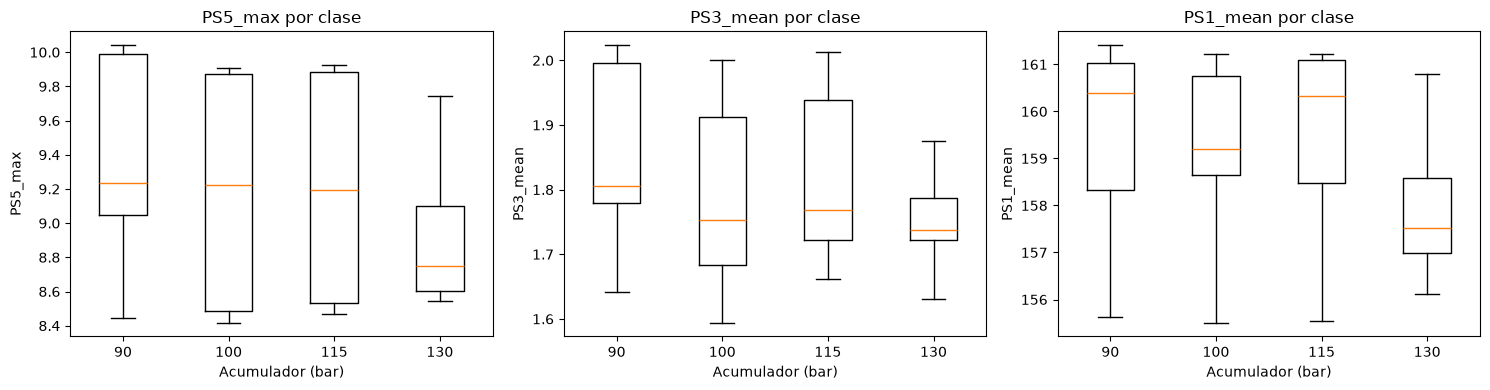

In [6]:
def q25(serie):
    return serie.quantile(0.25)

def q75(serie):
    return serie.quantile(0.75)

resumen_presion = X[elegidas].assign(bar=y.map(clases_bar)).groupby("bar").agg(
    ["median", q25, q75]
)
display(resumen_presion.round(3))
fig, ejes = plt.subplots(1, len(elegidas), figsize=(5 * len(elegidas), 4))
for ax, variable in zip(np.atleast_1d(ejes), elegidas):
    datos = [X.loc[y == clase, variable] for clase in sorted(clases_bar)]
    ax.boxplot(datos, tick_labels=[str(clases_bar[c]) for c in sorted(clases_bar)],
               showfliers=False)
    ax.set(xlabel="Acumulador (bar)", ylabel=variable,
           title=f"{variable} por clase")
plt.tight_layout()
plt.show()

## 5. Hallazgos, decisiones y límites

- **Calidad:** los 1.827 ciclos de entrenamiento tienen 68 variables numéricas, sin nulos, infinitos ni filas idénticas. Cuatro columnas son constantes (`PS2_min`, `PS3_min`, `FS1_min`, `SE_min`). No hay motivo observado para borrar ciclos. El filtro del `Pipeline` retira las constantes al ajustarse.
- **Balance:** 90 bar es la clase más frecuente (686; 37,5 %) y 100/115 bar tienen 317 ciclos cada una (17,4 %). Por eso la métrica principal es F1 macro, además de métricas por clase.
- **Grupos:** hay 111 combinaciones en entrenamiento; los tres grupos mayores reúnen 672 ciclos (36,8 % del entrenamiento). Cada uno ocupa más de la mitad de uno de los tres primeros pliegues. Es imprescindible informar resultados por pliegue y no crear una partición aleatoria por filas.
- **Redundancia:** existen 337 pares de variables con `|r| > 0,95` y 102 con `|r| > 0,995`. Se estandariza por las distintas unidades físicas y se aplica el filtro de correlación únicamente dentro del `Pipeline` para evitar fugas.
- **Variables de presión para José:** `PS5_max`, `PS3_mean` y `PS1_mean` son la propuesta exploratoria con correlación mutua menor que 0,95. Sus F1 macro individuales por grupos son aproximadamente 0,475, 0,352 y 0,302. Ayudan a describir tendencias, especialmente la presión óptima, pero las distribuciones se solapan y **no** bastan como clasificador de cuatro clases.
- **Alcance:** el dataset procede de un solo banco de laboratorio, con estados simultáneos de otros componentes. La marca `stable` se excluye porque no es una lectura de sensor disponible en uso real. Las asociaciones observadas no prueban causalidad ni generalización a otras instalaciones. El conjunto de prueba sigue reservado.